# Fraud Detection Model Training

This notebook walks through the full model-building process:
1. Load & inspect data
2. Simulate velocity counters (replaying CSV chronologically)
3. Combine all features
4. Time-based train/test split
5. Handle class imbalance
6. Train RandomForest + XGBoost
7. Evaluate both models
8. Save the best model

**Run cells one at a time** — each section builds on the previous.

## Section 1 — Load & Inspect Data

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import bisect

# Run this notebook from the project root: jupyter notebook
df = pd.read_csv("../app/data/Fraud_Data.csv")
df["signup_time"] = pd.to_datetime(df["signup_time"])
df["purchase_time"] = pd.to_datetime(df["purchase_time"])

# CRITICAL: sort by purchase_time before doing anything else.
# Velocity features look backward in time — if we don't sort first,
# we'd be computing features using "future" transactions.
df = df.sort_values("purchase_time").reset_index(drop=True)

print(f"Rows: {len(df):,}")
print(f"Date range: {df['purchase_time'].min()} → {df['purchase_time'].max()}")
df.head()

Rows: 151,112
Date range: 2015-01-01 00:00:44 → 2015-12-16 02:56:05


,user_id,signup_time,purchase_time,purchase_value,device_id,source,browser,sex,age,ip_address,class
0,309557,2015-01-01 00:00:43,2015-01-01 00:00:44,14,BBPACGBUVJUXF,Ads,Chrome,F,38,2.001426e+09,1
1,124539,2015-01-01 00:00:44,2015-01-01 00:00:45,14,BBPACGBUVJUXF,Ads,Chrome,F,38,2.001426e+09,1
2,161246,2015-01-01 00:00:45,2015-01-01 00:00:46,14,BBPACGBUVJUXF,Ads,Chrome,F,38,2.001426e+09,1
3,356414,2015-01-01 00:00:46,2015-01-01 00:00:47,14,BBPACGBUVJUXF,Ads,Chrome,F,38,2.001426e+09,1
4,338656,2015-01-01 00:00:47,2015-01-01 00:00:48,14,BBPACGBUVJUXF,Ads,Chrome,F,38,2.001426e+09,1


In [24]:
# Load IP→country lookup table from CSV using binary search (O(log n) per lookup).
# Same bisect approach as the velocity simulation — no PostgreSQL needed here.
ip_csv = pd.read_csv("../app/data/IpAddress_to_Country.csv")
_ip_from = ip_csv["lower_bound_ip_address"].values  # already sorted ascending
_ip_to   = ip_csv["upper_bound_ip_address"].values
_ip_ctry = ip_csv["country"].values

def lookup_ip_country(ip_float):
    if pd.isna(ip_float):
        return "Unknown"
    ip_int = int(ip_float)
    idx = bisect.bisect_right(_ip_from, ip_int) - 1
    if idx >= 0 and ip_int <= _ip_to[idx]:
        return _ip_ctry[idx]
    return "Unknown"

df["ip_country"] = df["ip_address"].apply(lookup_ip_country)
print(f"IP country lookup done. Top countries:")
print(df["ip_country"].value_counts().head(10))

IP country lookup done. Top countries:
ip_country
United States        58049
Unknown              21966
China                12038
Japan                 7306
United Kingdom        4490
Korea Republic of     4162
Germany               3646
France                3161
Canada                2975
Brazil                2961
Name: count, dtype: int64


class
0    136961
1     14151
Name: count, dtype: int64

Fraud rate: 9.4%


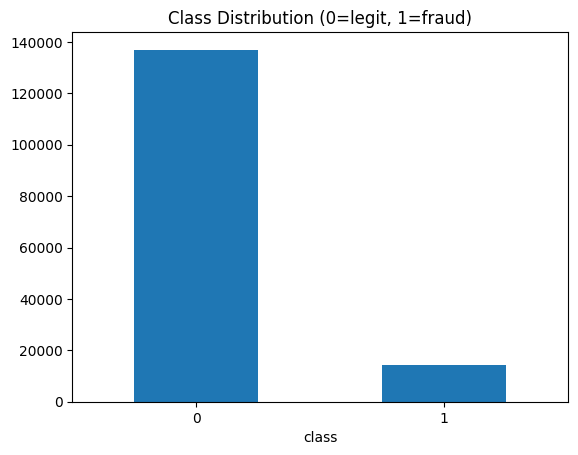

In [25]:
# Check class balance — fraud detection datasets are almost always imbalanced
counts = df["class"].value_counts()
print(counts)
print(f"\nFraud rate: {counts[1] / len(df) * 100:.1f}%")

counts.plot(kind="bar", title="Class Distribution (0=legit, 1=fraud)")
plt.xticks(rotation=0)
plt.show()

In [26]:
# Quick look at raw feature distributions
df[["purchase_value", "age"]].describe()

,purchase_value,age
count,151112.000000,151112.000000
mean,36.935372,33.140704
std,18.322762,8.617733
min,9.000000,18.000000
25%,22.000000,27.000000
50%,35.000000,33.000000
75%,49.000000,39.000000
max,154.000000,76.000000


In [27]:
# Categorical columns
for col in ["source", "browser", "sex"]:
    print(f"\n{col}:")
    print(df[col].value_counts())


source:
source
SEO       60615
Ads       59881
Direct    30616
Name: count, dtype: int64

browser:
browser
Chrome     61432
IE         36727
Safari     24667
FireFox    24610
Opera       3676
Name: count, dtype: int64

sex:
sex
M    88293
F    62819
Name: count, dtype: int64


In [ ]:
from collections import defaultdict
import bisect
from tqdm import tqdm

# Running sorted history per entity
did_uid_times = defaultdict(list)
did_uid_users = defaultdict(list)
uid_did_times = defaultdict(list)
uid_did_devs  = defaultdict(list)
ip_uid_times  = defaultdict(list)
ip_uid_users  = defaultdict(list)
pur_all_times = defaultdict(list)
pur_all_vals  = defaultdict(list)
pur_suc_times = defaultdict(list)
pur_suc_vals  = defaultdict(list)
did_txn_times = defaultdict(list)   # device_id -> [all transaction timestamps, no dedup]
uid_last_ts:  dict = {}             # user_id -> timestamp of most recent transaction
did_first_seen = {}                 # (device_id, user_id) -> first purchase_time
country_txn_times = defaultdict(list)  # ip_country -> [timestamps of all transactions]

WINDOWS = {
    "2h":  2  * 3600,
    "24h": 24 * 3600,
    "7d":  7  * 86400,
    "30d": 30 * 86400,
    "90d": 90 * 86400,
}

def count_distinct_in_window(times_list, vals_list, cutoff_ts):
    """Count distinct values in times_list that are >= cutoff_ts."""
    idx = bisect.bisect_left(times_list, cutoff_ts)
    return len(set(vals_list[idx:]))

def count_and_sum_in_window(times_list, vals_list, cutoff_ts):
    """Count entries and sum values in times_list >= cutoff_ts."""
    idx = bisect.bisect_left(times_list, cutoff_ts)
    vals = vals_list[idx:]
    return len(vals), sum(vals)

def median_in_window(times_list, vals_list, cutoff_ts):
    """Return median of vals in times_list that are >= cutoff_ts.
    Returns 0.0 if no prior transactions exist in the window."""
    idx = bisect.bisect_left(times_list, cutoff_ts)
    vals = vals_list[idx:]
    if not vals:
        return 0.0
    return float(np.median(vals))

def count_in_window(times_list, cutoff_ts):
    """Count entries in times_list that are >= cutoff_ts."""
    idx = bisect.bisect_left(times_list, cutoff_ts)
    return len(times_list) - idx

print("Helper functions defined. Ready to simulate.")

In [ ]:
# This cell takes ~2-4 minutes for 151k rows.
rows = []

for _, row in tqdm(df.iterrows(), total=len(df), desc="Simulating velocity"):
    ts  = row["purchase_time"].timestamp()
    uid = str(row["user_id"])
    did = str(row["device_id"])
    ip  = row["ip_address"]
    val = row["purchase_value"]
    country = row["ip_country"]
    is_fraud = row["class"]

    feat = {}

    # --- did_uid: distinct users seen on this device ---
    for w in ["2h", "24h", "7d", "30d", "90d"]:
        feat[f"did_uid_{w}"] = count_distinct_in_window(
            did_uid_times[did], did_uid_users[did], ts - WINDOWS[w])

    # --- uid_did: distinct devices seen for this user ---
    for w in ["2h", "24h", "7d", "30d", "90d"]:
        feat[f"uid_did_{w}"] = count_distinct_in_window(
            uid_did_times[uid], uid_did_devs[uid], ts - WINDOWS[w])

    # --- ip_uid: distinct users seen from this IP (2h, 24h, 7d only) ---
    for w in ["2h", "24h", "7d"]:
        feat[f"ip_uid_{w}"] = count_distinct_in_window(
            ip_uid_times[ip], ip_uid_users[ip], ts - WINDOWS[w])

    # --- purchase counts & amounts (all transactions) ---
    for w in ["24h", "7d", "30d", "90d"]:
        cnt, amt = count_and_sum_in_window(
            pur_all_times[uid], pur_all_vals[uid], ts - WINDOWS[w])
        feat[f"purchase_cnt_{w}"] = cnt
        feat[f"purchase_amt_{w}"] = amt

    # --- purchase counts & amounts (successful only: class=0 as proxy) ---
    for w in ["24h", "7d", "30d", "90d"]:
        cnt, amt = count_and_sum_in_window(
            pur_suc_times[uid], pur_suc_vals[uid], ts - WINDOWS[w])
        feat[f"purchase_success_cnt_{w}"] = cnt
        feat[f"purchase_success_amt_{w}"] = amt

    # --- did_uid_days_on_file ---
    key = (did, uid)
    if key not in did_first_seen:
        did_first_seen[key] = row["purchase_time"]
        feat["did_uid_days_on_file"] = 0
    else:
        feat["did_uid_days_on_file"] = (row["purchase_time"] - did_first_seen[key]).days

    # --- Median purchase amount in last 90d (uid-keyed) ---
    feat["pur_median_amt_90d"] = median_in_window(
        pur_all_times[uid], pur_all_vals[uid], ts - WINDOWS["90d"])

    # --- Transaction count for this device across windows (all txns, no dedup) ---
    for w in ["2h", "24h", "7d", "30d"]:
        idx = bisect.bisect_left(did_txn_times[did], ts - WINDOWS[w])
        feat[f"did_txn_cnt_{w}"] = len(did_txn_times[did]) - idx

    # --- Time since this user's last transaction (0 = first-ever transaction) ---
    feat["time_since_last_txn_uid"] = ts - uid_last_ts.get(uid, ts)

    # --- Country-level transaction counts (24h, 7d, 30d) ---
    # Counts how many transactions from this country were seen before this one.
    # High values signal geographic fraud clusters.
    for w in ["24h", "7d", "30d"]:
        feat[f"country_txn_count_{w}"] = count_in_window(
            country_txn_times[country], ts - WINDOWS[w])

    rows.append(feat)

    # Append to history AFTER computing features — transaction must not see itself
    did_uid_times[did].append(ts);  did_uid_users[did].append(uid)
    uid_did_times[uid].append(ts);  uid_did_devs[uid].append(did)
    ip_uid_times[ip].append(ts);    ip_uid_users[ip].append(uid)
    pur_all_times[uid].append(ts);  pur_all_vals[uid].append(val)
    did_txn_times[did].append(ts)
    uid_last_ts[uid] = ts
    country_txn_times[country].append(ts)
    if is_fraud == 0:
        pur_suc_times[uid].append(ts)
        pur_suc_vals[uid].append(val)

vel_df = pd.DataFrame(rows)
print(f"Velocity simulation done. Shape: {vel_df.shape}")
vel_df.head()

In [ ]:
# Raw transaction features
# Categorical columns (sex, source, browser) are label-encoded: each unique string
# gets an integer. Tree models (RF, XGBoost) don't need one-hot encoding.
# Missing values are filled with -1 so the model can distinguish "missing" from 0.

ip_country_cat = pd.Categorical(df["ip_country"])

feat_raw = pd.DataFrame({
    "purchase_value":    df["purchase_value"],
    "age":               df["age"].fillna(-1).astype(int),
    "days_since_signup": (df["purchase_time"] - df["signup_time"]).dt.days
                         .fillna(-999).astype(int),
    "sex":               df["sex"].map({"M": 0, "F": 1}).fillna(-1).astype(int),
    "source":            pd.Categorical(df["source"]).codes,
    "browser":           pd.Categorical(df["browser"]).codes,
    "ip_country_code":   ip_country_cat.codes,  # int; -1 = Unknown
    "hour_of_day":       df["purchase_time"].dt.hour,
    "day_of_week":       df["purchase_time"].dt.dayofweek,  # 0=Monday, 6=Sunday
    "month_of_year":     df["purchase_time"].dt.month,
})

X = pd.concat([feat_raw.reset_index(drop=True), vel_df], axis=1)
y = df["class"]

print(f"Feature matrix shape: {X.shape}")
print(f"\nFeature columns ({len(X.columns)}):")
print(list(X.columns))

In [31]:
# --- Derived features ---
# These combine raw and velocity columns into higher-level signals.

# How does this purchase compare to the user's recent average spend?
# A value >> 1 means the transaction is unusually large for this user.
# .clip(lower=1) on the denominator avoids division by zero.
user_avg_amt_30d = X["purchase_amt_30d"] / X["purchase_cnt_30d"].clip(lower=1)
X["amount_vs_user_avg_30d"] = X["purchase_value"] / user_avg_amt_30d.clip(lower=1)

# Customer age minus account tenure in years.
# A large positive gap means the account was opened recently relative to age —
# a potential signal for synthetic or stolen-identity accounts.
X["age_account_gap"] = X["age"] - X["days_since_signup"] / 365

# Binary flag: is this purchase > 2x the user's median spend over the past 90 days?
# 0 when there is no prior history (pur_median_amt_90d == 0 -> first-time buyer, not flagged).
X["high_amount_vs_hist"] = (
    (X["pur_median_amt_90d"] > 0) &
    (X["purchase_value"] > 2 * X["pur_median_amt_90d"])
).astype(int)

print("Derived features added: amount_vs_user_avg_30d, device_txn_rate_1h, age_account_gap, high_amount_vs_hist")
print(f"Feature matrix shape: {X.shape}")
print(f"high_amount_vs_hist value counts:")
print(X["high_amount_vs_hist"].value_counts())


Derived features added: amount_vs_user_avg_30d, device_txn_rate_1h, age_account_gap, high_amount_vs_hist
Feature matrix shape: (151112, 46)
high_amount_vs_hist value counts:
high_amount_vs_hist
0    151112
Name: count, dtype: int64


In [32]:
# Sanity check: no NaN values (tree models can handle NaN in XGBoost
# but RandomForest cannot)
print("NaN counts per column:")
print(X.isna().sum()[X.isna().sum() > 0])
print("(empty = no NaNs, good!)")

NaN counts per column:
Series([], dtype: int64)
(empty = no NaNs, good!)


## Section 4 — Time-Based Train/Test Split

**Why NOT a random split?**  
Our velocity features look backward in time. If we split randomly, a test row from January
might have a training row from February in its "history" — the model would learn from future
information that won't exist in production. This is called **data leakage**.

By splitting at the 80th percentile of time, the test set only contains transactions that
happened after all training transactions. This mirrors real deployment.

In [33]:
split_idx = int(len(X) * 0.80)
split_time = df["purchase_time"].iloc[split_idx]

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Split at: {split_time}")
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows")
print(f"Train fraud rate: {y_train.mean()*100:.1f}%")
print(f"Test fraud rate:  {y_test.mean()*100:.1f}%")

Split at: 2015-08-30 15:18:56
Train: 120,889 rows | Test: 30,223 rows
Train fraud rate: 10.6%
Test fraud rate:  4.6%


## Section 4b — WOE Encoding for `age`

`age` is binned using `OptimalBinning` from the `optbinning` library.
Bins are **fit on training data only** (no leakage). The `age = -1` sentinel
(missing age) is treated as its own special bin via `special_codes=[-1]`.
The raw `age` column is then replaced by `age_woe` (a float WOE value) in both
train and test sets.

In [34]:
from sklearn.tree import DecisionTreeClassifier
import numpy as np

# Use a shallow decision tree to find optimal age bin boundaries on training data only.
# This is equivalent to WOE monotonic binning for tree-based models:
# the tree finds the splits that best separate fraud from non-fraud.
#
# max_leaf_nodes=6  → at most 5 boundaries = at most 6 age groups
# min_samples_leaf=0.05 → each bin must contain at least 5% of training rows
#                         (prevents tiny, unstable bins)
age_tree = DecisionTreeClassifier(
    max_leaf_nodes=6,
    min_samples_leaf=0.05,
    random_state=42,
)
age_tree.fit(X_train[["age"]], y_train)

# Extract the split thresholds the tree chose
thresholds = sorted(set(age_tree.tree_.threshold[age_tree.tree_.threshold != -2]))
bins = [-np.inf] + thresholds + [np.inf]

print(f"Age bin boundaries: {[round(t, 1) for t in thresholds]}")
print(f"Number of age groups: {len(bins) - 1}")

# Show fraud rate per bin so you can see the monotonic pattern
labels = list(range(len(bins) - 1))
train_groups = pd.cut(X_train["age"], bins=bins, labels=labels).astype(float)
summary = pd.DataFrame({"age_group": train_groups, "fraud": y_train.values})
print("\nBin summary (training data):")
print(summary.groupby("age_group")["fraud"]
      .agg(count="count", fraud_rate="mean")
      .round(4))

Age bin boundaries: [np.float64(22.5), np.float64(24.5), np.float64(27.5), np.float64(42.5), np.float64(46.5)]
Number of age groups: 6

Bin summary (training data):
           count  fraud_rate
age_group                   
0.0        13580      0.0976
1.0         7591      0.1162
2.0        13189      0.0902
3.0        68862      0.1100
4.0         8869      0.0941
5.0         8798      0.1087


In [35]:
X_train = X_train.copy()
X_test  = X_test.copy()

# Assign each age to its bin index (0, 1, 2, …) using the boundaries from above.
# Note: the -1 sentinel (missing age) falls into bin 0 since -inf < -1 < first threshold.
#       Tree models will learn to treat it as its own pattern within that bin.
X_train["age_group"] = pd.cut(X_train["age"], bins=bins, labels=labels).astype(int)
X_test["age_group"]  = pd.cut(X_test["age"],  bins=bins, labels=labels).astype(int)

# Drop the raw age column from both splits.
X_train = X_train.drop(columns=["age"])
X_test  = X_test.drop(columns=["age"])

print("Columns after encoding:")
print(list(X_train.columns))
print(f"\nX_train shape: {X_train.shape} | X_test shape: {X_test.shape}")
print(f"\nage_group value counts (train):\n{X_train['age_group'].value_counts().sort_index()}")

Columns after encoding:
['purchase_value', 'days_since_signup', 'sex', 'source', 'browser', 'ip_country_code', 'did_uid_2h', 'did_uid_24h', 'did_uid_7d', 'did_uid_30d', 'did_uid_90d', 'uid_did_2h', 'uid_did_24h', 'uid_did_7d', 'uid_did_30d', 'uid_did_90d', 'ip_uid_2h', 'ip_uid_24h', 'ip_uid_7d', 'purchase_cnt_24h', 'purchase_amt_24h', 'purchase_cnt_7d', 'purchase_amt_7d', 'purchase_cnt_30d', 'purchase_amt_30d', 'purchase_cnt_90d', 'purchase_amt_90d', 'purchase_success_cnt_24h', 'purchase_success_amt_24h', 'purchase_success_cnt_7d', 'purchase_success_amt_7d', 'purchase_success_cnt_30d', 'purchase_success_amt_30d', 'purchase_success_cnt_90d', 'purchase_success_amt_90d', 'did_uid_days_on_file', 'pur_median_amt_90d', 'did_txn_cnt_2h', 'did_txn_cnt_24h', 'did_txn_cnt_7d', 'did_txn_cnt_30d', 'time_since_last_txn_uid', 'amount_vs_user_avg_30d', 'age_account_gap', 'high_amount_vs_hist', 'age_group']

X_train shape: (120889, 46) | X_test shape: (30223, 46)

age_group value counts (train):
age_g

## Section 5 — Handle Class Imbalance

With ~9% fraud, a model that always predicts "not fraud" gets ~91% accuracy — useless.
We need the model to weight fraud cases more heavily during training.

- **RandomForest:** `class_weight='balanced'` — sklearn computes weights automatically
- **XGBoost:** `scale_pos_weight=ratio` — weights the positive class by this factor

We skip SMOTE (synthetic oversampling) here because synthetic rows would have velocity
features that don't correspond to any real sequence of events.

In [36]:
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
ratio = neg / pos

print(f"Training set — legit: {neg:,} | fraud: {pos:,}")
print(f"Imbalance ratio: {ratio:.1f}:1")
print(f"XGBoost scale_pos_weight will be set to: {ratio:.1f}")

Training set — legit: 108,127 | fraud: 12,762
Imbalance ratio: 8.5:1
XGBoost scale_pos_weight will be set to: 8.5


## Section 6 — Train Both Models

In [37]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,    # 200 trees — more trees = more stable, diminishing returns after ~200
    max_depth=10,        # limit depth to avoid memorizing training data
    class_weight="balanced",  # auto-reweight: each class gets total_samples / (n_classes * count)
    n_jobs=-1,           # use all CPU cores
    random_state=42,
)

print("Training RandomForest...")
rf.fit(X_train, y_train)
print("Done!")

Training RandomForest...
Done!


In [38]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,        # more trees than RF because each XGBoost tree is shallow
    max_depth=6,             # XGBoost works best with shallower trees
    learning_rate=0.1,       # how much each tree contributes; lower = more trees needed
    scale_pos_weight=ratio,  # weight the fraud class by the imbalance ratio
    eval_metric="aucpr",     # monitor PR-AUC (better for imbalanced data than AUC-ROC)
    random_state=42,
)

print("Training XGBoost (prints eval every 50 rounds)...")
xgb.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=50,
)
print("Done!")

Training XGBoost (prints eval every 50 rounds)...
[0]	validation_0-aucpr:0.09189
[50]	validation_0-aucpr:0.09234
[100]	validation_0-aucpr:0.09193
[150]	validation_0-aucpr:0.08920
[200]	validation_0-aucpr:0.08890
[250]	validation_0-aucpr:0.08706
[299]	validation_0-aucpr:0.08579
Done!


## Section 7 — Evaluate Both Models

**Key metrics for fraud detection:**
- **Precision** (of fraud predictions): when we call something fraud, how often are we right?
- **Recall** (of actual fraud): what fraction of real fraud do we catch?
- **PR-AUC** (area under the precision-recall curve): the best single number for imbalanced classification
- **ROC-AUC**: good for comparing models, but can be misleadingly high on imbalanced data

The confusion matrix shows:
- **True Positives (TP):** fraud correctly caught
- **False Positives (FP):** legitimate transactions wrongly blocked
- **False Negatives (FN):** fraud that slipped through

In [39]:
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, average_precision_score,
    ConfusionMatrixDisplay, PrecisionRecallDisplay,
)

results = {}

for name, model in [("RandomForest", rf), ("XGBoost", xgb)]:
    y_pred  = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    roc_auc = roc_auc_score(y_test, y_proba)
    pr_auc  = average_precision_score(y_test, y_proba)
    results[name] = {"roc_auc": roc_auc, "pr_auc": pr_auc, "model": model}

    print(f"\n{'='*40}")
    print(f"  {name}")
    print(f"{'='*40}")
    print(classification_report(y_test, y_pred, target_names=["legit", "fraud"]))
    print(f"ROC-AUC : {roc_auc:.4f}")
    print(f"PR-AUC  : {pr_auc:.4f}  ← primary metric")


  RandomForest
              precision    recall  f1-score   support

       legit       0.96      0.98      0.97     28834
       fraud       0.25      0.12      0.17      1389

    accuracy                           0.94     30223
   macro avg       0.60      0.55      0.57     30223
weighted avg       0.93      0.94      0.93     30223

ROC-AUC : 0.5502
PR-AUC  : 0.0901  ← primary metric

  XGBoost
              precision    recall  f1-score   support

       legit       0.96      0.98      0.97     28834
       fraud       0.22      0.12      0.15      1389

    accuracy                           0.94     30223
   macro avg       0.59      0.55      0.56     30223
weighted avg       0.92      0.94      0.93     30223

ROC-AUC : 0.5477
PR-AUC  : 0.0862  ← primary metric


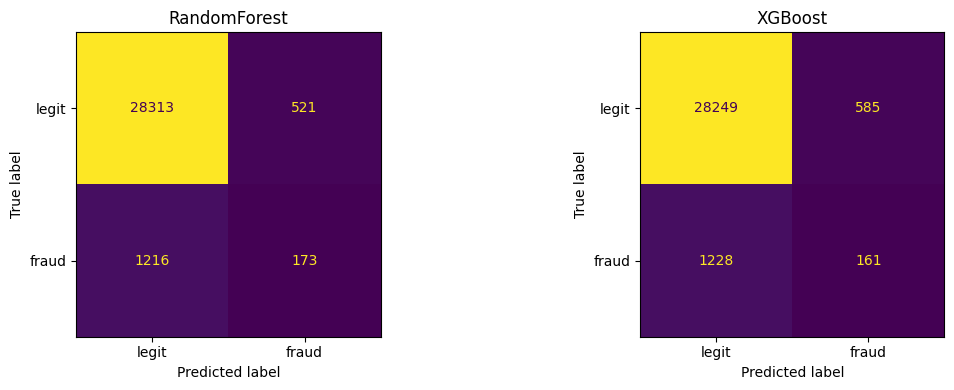

In [40]:
# Confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, model) in zip(axes, [("RandomForest", rf), ("XGBoost", xgb)]):
    cm = confusion_matrix(y_test, model.predict(X_test))
    disp = ConfusionMatrixDisplay(cm, display_labels=["legit", "fraud"])
    disp.plot(ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [41]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Set your desired threshold here. Run this cell to see the precision/recall trade-off,
# then adjust THRESHOLD and re-run the evaluation cell below.
# Higher threshold → higher precision (fewer legit transactions wrongly denied)
#                  → lower recall (more fraud slips through)
THRESHOLD = 0.7   # ← change this value, then re-run the evaluation cell above


print(f"{'Threshold':>10} {'Precision':>10} {'Recall':>10} {'F1':>8}")
print("-" * 42)
for t in np.arange(0.3, 0.95, 0.05):
    y_hat = (results["XGBoost"]["model"].predict_proba(X_test)[:, 1] >= t).astype(int)
    p = precision_score(y_test, y_hat, zero_division=0)
    r = recall_score(y_test, y_hat, zero_division=0)
    f = f1_score(y_test, y_hat, zero_division=0)
    marker = " ← selected" if abs(t - THRESHOLD) < 0.001 else ""
    print(f"{t:>10.2f} {p:>10.3f} {r:>10.3f} {f:>8.3f}{marker}")

 Threshold  Precision     Recall       F1
------------------------------------------
      0.30      0.066      0.294    0.108
      0.35      0.095      0.184    0.125
      0.40      0.143      0.143    0.143
      0.45      0.185      0.126    0.150
      0.50      0.216      0.116    0.151
      0.55      0.234      0.108    0.148
      0.60      0.237      0.091    0.131
      0.65      0.250      0.073    0.114
      0.70      0.296      0.058    0.096 ← selected
      0.75      0.331      0.040    0.071
      0.80      0.324      0.017    0.033
      0.85      0.320      0.006    0.011
      0.90      0.333      0.001    0.001


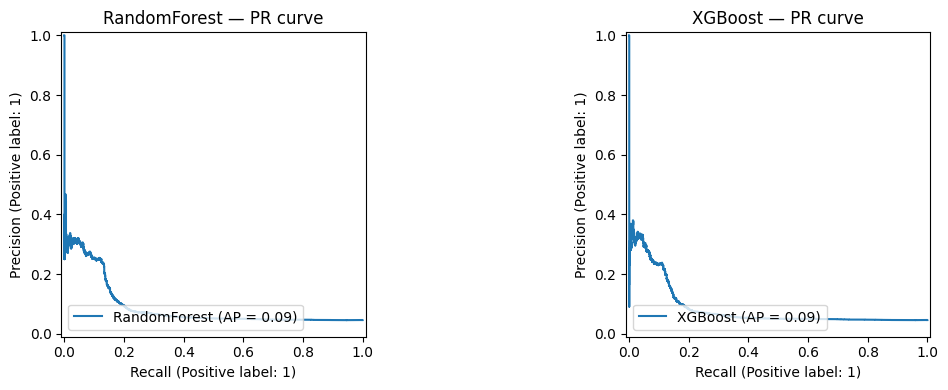

In [42]:
# Precision-Recall curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, model) in zip(axes, [("RandomForest", rf), ("XGBoost", xgb)]):
    y_proba = model.predict_proba(X_test)[:, 1]
    PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=ax, name=name)
    ax.set_title(f"{name} — PR curve")

plt.tight_layout()
plt.show()

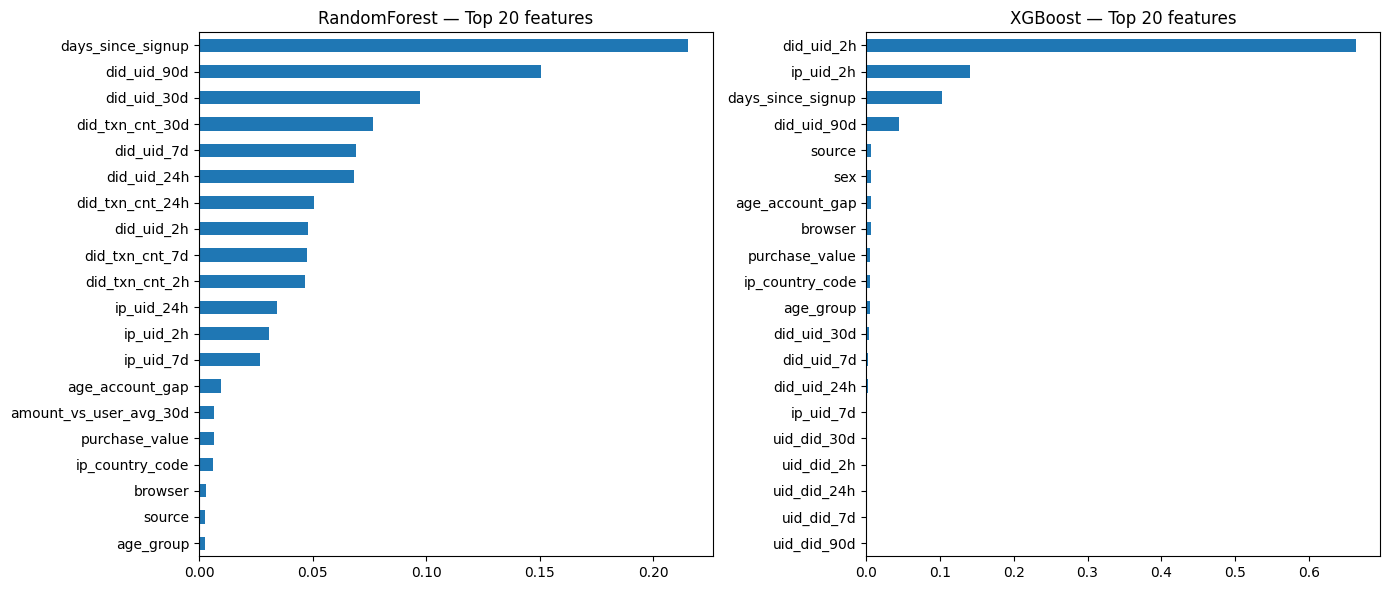

In [43]:
# Feature importances
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (name, model) in zip(axes, [("RandomForest", rf), ("XGBoost", xgb)]):
    importances = pd.Series(model.feature_importances_, index=X_train.columns)
    importances.nlargest(20).sort_values().plot(kind="barh", ax=ax)
    ax.set_title(f"{name} — Top 20 features")

plt.tight_layout()
plt.show()

## Section 8 — Save the Best Model

We save:
1. **`model.joblib`** — the trained model object
2. **`model_features.json`** — the exact list of feature column names in training order

The feature list is critical: when `models.py` builds a prediction row from a `Features`
object at inference time, it must use the exact same column order as training.
If they're out of order, the model sees the wrong values for each feature.

In [50]:
import joblib, json

# Pick the model with the higher PR-AUC
best_name = max(results, key=lambda k: results[k]["pr_auc"])
best_model = results[best_name]["model"]

print(f"Best model: {best_name}")
print(f"  RF  PR-AUC: {results['RandomForest']['pr_auc']:.4f}")
print(f"  XGB PR-AUC: {results['XGBoost']['pr_auc']:.4f}")

joblib.dump(best_model, "../app/decisions/model.joblib")

with open("../app/decisions/model_features.json", "w") as f:
    json.dump(list(X_train.columns), f, indent=2)

# Save the age bin boundaries so inference code can apply the same binning at runtime.
with open("../app/decisions/age_bins.json", "w") as f:
    json.dump({"bins": [b if np.isfinite(b) else None for b in bins]}, f, indent=2)

print(f"\nSaved model to: app/decisions/model.joblib")
print(f"Saved feature list to: app/decisions/model_features.json")
print(f"Saved age bin boundaries to: app/decisions/age_bins.json")

Best model: RandomForest
  RF  PR-AUC: 0.0901
  XGB PR-AUC: 0.0862

Saved model to: app/decisions/model.joblib
Saved feature list to: app/decisions/model_features.json
Saved age bin boundaries to: app/decisions/age_bins.json


In [51]:
# Quick smoke test: load the saved model and make a prediction
loaded = joblib.load("../app/decisions/model.joblib")
with open("../app/decisions/model_features.json") as f:
    feature_names = json.load(f)

# Build a dummy row (all zeros) and predict
dummy = pd.DataFrame([[0] * len(feature_names)], columns=feature_names)
proba = loaded.predict_proba(dummy)[0][1]
print(f"Loaded model OK. Dummy row fraud probability: {proba:.4f}")
print(f"Feature count: {len(feature_names)}")

Loaded model OK. Dummy row fraud probability: 0.4072
Feature count: 46
